In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from collections import Counter
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from pathlib import Path

In [2]:
TRAIN_PATH = "train.csv"
LABELS_PATH = "train_labels.csv"
TEST_PATH = "test.csv"

RANDOM_STATE = 42
CHUNK_SIZE = 250_000

Labels shape: (424116, 4)
Unique base sessions: 23562
Unique session-question IDs: 424116

Question counts:


,observations
question_number,
1,23562
2,23562
3,23562
4,23562
5,23562
6,23562
7,23562
8,23562
9,23562



Correctness by question:


,observations,accuracy
question_number,,
1,23562,0.7275
2,23562,0.9788
3,23562,0.9340
4,23562,0.7982
5,23562,0.5483
6,23562,0.7760
7,23562,0.7361
8,23562,0.6172
9,23562,0.7363


Questions assigned to each expected level group:


,question_min,question_max,number_of_questions,number_of_labels
expected_level_group,,,,
0-4,1,3,3,70686
5-12,4,13,10,235620
13-22,14,18,5,117810


Events found in the scanned chunk: 881

Checkpoint events:


,session_id,index,elapsed_time,event_name,name,level,text,fqid,level_group
164,20090312431273200,164,194860,checkpoint,basic,4,NaN,chap1_finale_c,0-4
460,20090312431273200,470,499235,checkpoint,basic,12,NaN,chap2_finale_c,5-12
880,20090312431273200,931,1272679,checkpoint,basic,22,NaN,chap4_finale_c,13-22



First 10 events:


,session_id,index,elapsed_time,event_name,name,level,text,fqid,level_group
0,20090312431273200,0,0,cutscene_click,basic,0,undefined,intro,0-4
1,20090312431273200,1,1323,person_click,basic,0,"Whatcha doing over there, Jo?",gramps,0-4
2,20090312431273200,2,831,person_click,basic,0,Just talking to Teddy.,gramps,0-4
3,20090312431273200,3,1147,person_click,basic,0,I gotta run to my meeting!,gramps,0-4
4,20090312431273200,4,1863,person_click,basic,0,"Can I come, Gramps?",gramps,0-4
5,20090312431273200,5,3423,person_click,basic,0,"Sure thing, Jo. Grab your notebook and come up...",gramps,0-4
6,20090312431273200,6,5197,person_click,basic,0,"See you later, Teddy.",teddy,0-4
7,20090312431273200,7,6180,person_click,basic,0,I get to go to Gramps's meeting!,teddy,0-4
8,20090312431273200,8,7014,person_click,basic,0,Now where did I put my notebook?,teddy,0-4
9,20090312431273200,9,7946,person_click,basic,0,\u00f0\u0178\u02dc\u00b4,teddy,0-4


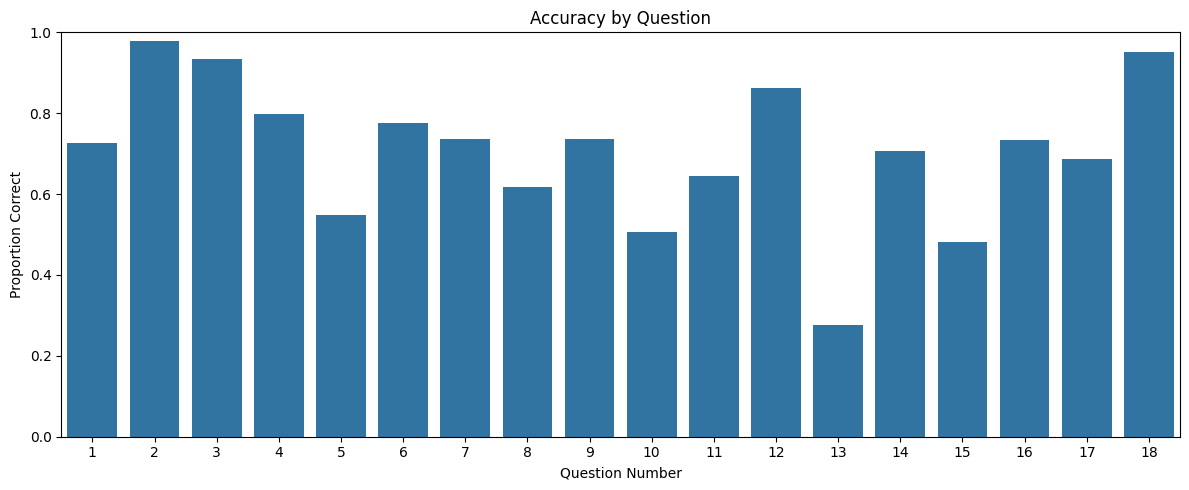

In [3]:
labels_check = pd.read_csv(LABELS_PATH)

# Extract question number and base session ID.
labels_check["question_number"] = (
    labels_check["session_id"]
    .str.extract(r"_q(\d+)$")
    .astype(int)
)

labels_check["base_session_id"] = (
    labels_check["session_id"]
    .str.replace(r"_q\d+$", "", regex=True)
)

print("Labels shape:", labels_check.shape)
print("Unique base sessions:",
      labels_check["base_session_id"].nunique())
print("Unique session-question IDs:",
      labels_check["session_id"].nunique())

print("\nQuestion counts:")
display(
    labels_check.groupby("question_number")
    .size()
    .rename("observations")
    .to_frame()
)

print("\nCorrectness by question:")
display(
    labels_check.groupby("question_number")["correct"]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "observations",
        "mean": "accuracy"
    })
    .round(4)
)

labels_check["expected_level_group"] = np.select(
    [
        labels_check["question_number"].between(1, 3),
        labels_check["question_number"].between(4, 13),
        labels_check["question_number"].between(14, 18),
    ],
    [
        "0-4",
        "5-12",
        "13-22",
    ],
    default="unknown"
)

print("Questions assigned to each expected level group:")
display(
    labels_check.groupby("expected_level_group")
    .agg(
        question_min = ("question_number", "min"),
        question_max = ("question_number", "max"),
        number_of_questions = ("question_number", "nunique"),
        number_of_labels = ("correct", "size")
    )
    .sort_values("question_min")
)
session_to_inspect = 20090312431273200

columns_to_inspect = [
    "session_id",
    "index",
    "elapsed_time",
    "event_name",
    "name",
    "level",
    "level_group",
    "fqid",
    "text",
]

session_events = None

for chunk in pd.read_csv(
    TRAIN_PATH,
    usecols=columns_to_inspect,
    chunksize=CHUNK_SIZE,
    low_memory=False
):
    matching = chunk[
        chunk["session_id"] == session_to_inspect
    ]

    if not matching.empty:
        session_events = matching.copy()
        break

if session_events is None:
    print("Session not found in the scanned chunks.")
else:
    session_events = session_events.sort_values("index")

    print("Events found in the scanned chunk:",
          len(session_events))

    print("\nCheckpoint events:")
    display(
        session_events[
            session_events["event_name"] == "checkpoint"
        ]
    )

    print("\nFirst 10 events:")
    display(session_events.head(10))

question_accuracy = (
    labels_check.groupby("question_number")["correct"]
    .mean()
)

plt.figure(figsize = (12, 5))
sns.barplot(
    x = question_accuracy.index,
    y = question_accuracy.values
)
plt.title("Accuracy by Question")
plt.xlabel("Question Number")
plt.ylabel("Proportion Correct")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [4]:
event_group_counts = Counter()

columns_needed = [
    "session_id",
    "event_name",
    "level_group",
]

for chunk in pd.read_csv(
    TRAIN_PATH,
    usecols=columns_needed,
    chunksize=CHUNK_SIZE,
    low_memory=False,
):
    partial_counts = (
        chunk.groupby(
            ["session_id", "level_group", "event_name"],
            observed=True
        )
        .size()
    )

    # Add this chunk's counts to the running totals.
    event_group_counts.update(partial_counts.to_dict())

print("Distinct session/group/event combinations:",
      len(event_group_counts))

event_count_series = pd.Series(
    event_group_counts,
    name="event_count"
)

event_count_series.index = pd.MultiIndex.from_tuples(
    event_count_series.index,
    names=["session_id", "level_group", "event_name"]
)

event_features = (
    event_count_series
    .unstack("event_name", fill_value=0)
    .reset_index()
)

event_features.columns = ( #give event-count columns clear, consistent names
    ["session_id", "level_group"]
    + [
        f"event_count_{col}"
        for col in event_features.columns[2:]
    ]
)

event_count_columns = [
    col for col in event_features.columns
    if col.startswith("event_count_")
]

event_features["total_events_in_group"] = ( #total events in each session and level group
    event_features[event_count_columns].sum(axis=1)
)

print("Feature table shape:", event_features.shape)
print("Unique sessions:", event_features["session_id"].nunique())

print("\nRows by level group:")
display(
    event_features.groupby("level_group")
    .size()
    .rename("session_group_rows")
    .to_frame()
)

print("\nExample feature rows:")
display(event_features.head())

Distinct session/group/event combinations: 734429
Feature table shape: (70686, 14)
Unique sessions: 23562

Rows by level group:


,session_group_rows
level_group,
0-4,23562
13-22,23562
5-12,23562



Example feature rows:


,session_id,level_group,event_count_checkpoint,event_count_cutscene_click,event_count_map_click,event_count_map_hover,event_count_navigate_click,event_count_notebook_click,event_count_notification_click,event_count_object_click,event_count_object_hover,event_count_observation_click,event_count_person_click,total_events_in_group
0,20090312431273200,0-4,1,28,2,4,81,0,8,11,4,4,22,165
1,20090312431273200,13-22,1,60,6,14,170,0,10,20,13,3,123,420
2,20090312431273200,5-12,1,12,8,9,103,0,9,28,21,1,104,296
3,20090312433251036,0-4,1,36,3,3,49,2,5,15,5,2,18,139
4,20090312433251036,13-22,1,65,45,186,637,50,14,83,66,5,145,1297


In [5]:
model_data = labels_check.copy()

model_data["label_row_id"] = np.arange(len(model_data)) #preserve the original order of the label rows

model_data["session_numeric_id"] = ( #convert the base session IDs to the integer format used in train.csv
    model_data["base_session_id"].astype("int64")
)

model_data = model_data.merge(
    event_features,
    left_on = [
        "session_numeric_id",
        "expected_level_group",
    ],
    right_on = [
        "session_id",
        "level_group",
    ],
    how = "left",
    validate = "many_to_one",
    indicator = True,
)

model_data = (
    model_data
    .sort_values("label_row_id")
    .reset_index(drop=True)
)

print("Model table shape:", model_data.shape)

print("\nFeature merge status:")
display(model_data["_merge"].value_counts())

print("\nMissing event-count values:")
print(
    model_data[event_count_columns]
    .isna()
    .sum()
    .sum()
)

print("\nExample matched rows:")
display(
    model_data[
        [
            "session_id_x",
            "question_number",
            "expected_level_group",
            "correct",
            "total_events_in_group",
        ]
    ].head()
)

Model table shape: (424116, 22)

Feature merge status:


_merge
both          424116
left_only          0
right_only         0
Name: count, dtype: int64


Missing event-count values:
0

Example matched rows:


,session_id_x,question_number,expected_level_group,correct,total_events_in_group
0,20090312431273200_q1,1,0-4,1,165
1,20090312433251036_q1,1,0-4,0,139
2,20090312455206810_q1,1,0-4,1,149
3,20090313091715820_q1,1,0-4,0,176
4,20090313571836404_q1,1,0-4,1,112


In [6]:
session_ids = model_data["base_session_id"].drop_duplicates() #split by unique session IDs, not individual question rows

development_sessions, test_sessions = train_test_split( #reserve 15% of sessions for the final test set
    session_ids,
    test_size = 0.15,
    random_state = RANDOM_STATE
)

train_sessions, val_sessions = train_test_split( #split the development sessions into training and validation sets
    development_sessions,
    test_size = 15 / 85,
    random_state = RANDOM_STATE
)

train_mask = model_data["base_session_id"].isin(train_sessions) #assign every question according to its session's split
val_mask = model_data["base_session_id"].isin(val_sessions)
test_mask = model_data["base_session_id"].isin(test_sessions)

print("Session counts:")
print("Training:", len(train_sessions))
print("Validation:", len(val_sessions))
print("Test:", len(test_sessions))

print("\nQuestion-row counts:")
print("Training:", train_mask.sum())
print("Validation:", val_mask.sum())
print("Test:", test_mask.sum())

# Verify that no session appears in more than one split.
print("\nOverlapping sessions:")
print("Train vs. validation:", len(set(train_sessions) & set(val_sessions)))
print("Train vs. test:", len(set(train_sessions) & set(test_sessions)))
print("Validation vs. test:", len(set(val_sessions) & set(test_sessions)))

Session counts:
Training: 16492
Validation: 3535
Test: 3535

Question-row counts:
Training: 296856
Validation: 63630
Test: 63630

Overlapping sessions:
Train vs. validation: 0
Train vs. test: 0
Validation vs. test: 0


In [7]:
train_data = model_data.loc[train_mask].copy() #select rows for each split based on the boolean masks
val_data = model_data.loc[val_mask].copy()
test_data = model_data.loc[test_mask].copy()

for split_name, split_data in [ #confirm the target distribution is reasonably consistent across splits
    ("Training", train_data),
    ("Validation", val_data),
    ("Test", test_data),
]:
    print(f"\n{split_name} target distribution:")
    print(split_data["correct"].value_counts(normalize = True).sort_index().round(4))


Training target distribution:
correct
0    0.2933
1    0.7067
Name: proportion, dtype: float64

Validation target distribution:
correct
0    0.2959
1    0.7041
Name: proportion, dtype: float64

Test target distribution:
correct
0    0.2977
1    0.7023
Name: proportion, dtype: float64


In [8]:
ARTIFACT_DIR = Path("model_artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)

train_data.to_pickle(ARTIFACT_DIR / "train_data.pkl") #save existing split to disk for use in Notebook 3
val_data.to_pickle(ARTIFACT_DIR / "val_data.pkl")
test_data.to_pickle(ARTIFACT_DIR / "test_data.pkl")

pd.to_pickle(event_count_columns, ARTIFACT_DIR / "event_count_columns.pkl") #preserve the event-count column names for consistent preprocessing.

print("Processed data and feature names saved.")

Processed data and feature names saved.


In [9]:
majority_model = DummyClassifier(strategy = "most_frequent") #establish a baseline model that always predicts the most frequent class
majority_model.fit(
    train_data[["question_number"]],
    train_data["correct"]
)

majority_predictions = majority_model.predict( #evaluate on the same validation rows used by both logistic regression models
    val_data[["question_number"]]
)
y_val_majority = val_data["correct"]

majority_accuracy = accuracy_score(y_val_majority, majority_predictions)
majority_precision = precision_score(
    y_val_majority, majority_predictions, zero_division=0
)
majority_recall = recall_score(
    y_val_majority, majority_predictions, zero_division=0
)
majority_f1 = f1_score(y_val_majority, majority_predictions, zero_division=0)

print(f"Majority baseline accuracy:  {majority_accuracy:.4f}")
print(f"Majority baseline precision: {majority_precision:.4f}")
print(f"Majority baseline recall:    {majority_recall:.4f}")
print(f"Majority baseline F1-score:  {majority_f1:.4f}")

Majority baseline accuracy:  0.7041
Majority baseline precision: 0.7041
Majority baseline recall:    1.0000
Majority baseline F1-score:  0.8263


In [10]:
feature_columns = ["question_number"] + event_count_columns #select features and targets from the same new training/validation split.

X_train_events = train_data[feature_columns]
X_val_events = val_data[feature_columns]

y_train_events = train_data["correct"]
y_val_events = val_data["correct"]

event_model = make_pipeline( #combinecategorical question identity with standardized event counts for logistic regression
    ColumnTransformer(
        transformers = [
            ("question", OneHotEncoder(handle_unknown = "ignore"), ["question_number"]),
            ("counts", StandardScaler(), event_count_columns),
        ]
    ),
    LogisticRegression(max_iter = 1000)
)

event_model.fit(X_train_events, y_train_events) #fit and evaluate using matching feature and target rows.
event_predictions = event_model.predict(X_val_events)

event_accuracy = accuracy_score(y_val_events, event_predictions)
event_precision = precision_score(
    y_val_events, event_predictions, zero_division=0
)
event_recall = recall_score(y_val_events, event_predictions, zero_division=0)
event_f1 = f1_score(y_val_events, event_predictions, zero_division=0)

print(f"Question + event-count accuracy:  {event_accuracy:.4f}")
print(f"Question + event-count precision: {event_precision:.4f}")
print(f"Question + event-count recall:    {event_recall:.4f}")
print(f"Question + event-count F1-score:  {event_f1:.4f}")

Question + event-count accuracy:  0.7442
Question + event-count precision: 0.7583
Question + event-count recall:    0.9345
Question + event-count F1-score:  0.8373


In [11]:
X_train_q = train_data[["question_number"]] #select the question-number feature and target from the current split
X_val_q = val_data[["question_number"]]
y_train_q = train_data["correct"]
y_val_q = val_data["correct"]

question_model = make_pipeline( #refit the question-only model using the current training data
    OneHotEncoder(handle_unknown = "ignore"),
    LogisticRegression(max_iter = 1000)
)

question_model.fit(X_train_q, y_train_q)
question_predictions = question_model.predict(X_val_q)

# Evaluate predictions on the current validation set.
question_accuracy = accuracy_score(y_val_q, question_predictions)
question_precision = precision_score(
    y_val_q, question_predictions, zero_division = 0
)
question_recall = recall_score(
    y_val_q, question_predictions, zero_division = 0
)
question_f1 = f1_score(y_val_q, question_predictions, zero_division = 0)

print(f"Question-only accuracy:  {question_accuracy:.4f}")
print(f"Question-only precision: {question_precision:.4f}")
print(f"Question-only recall:    {question_recall:.4f}")
print(f"Question-only F1-score:  {question_f1:.4f}")

Question-only accuracy:  0.7309
Question-only precision: 0.7447
Question-only recall:    0.9402
Question-only F1-score:  0.8311


,Model,Accuracy,Precision,Recall,F1-score
0,Majority-class baseline,0.7041,0.7041,1.0000,0.8263
1,Question-only logistic regression,0.7309,0.7447,0.9402,0.8311
2,Question + event-count logistic regression,0.7442,0.7583,0.9345,0.8373


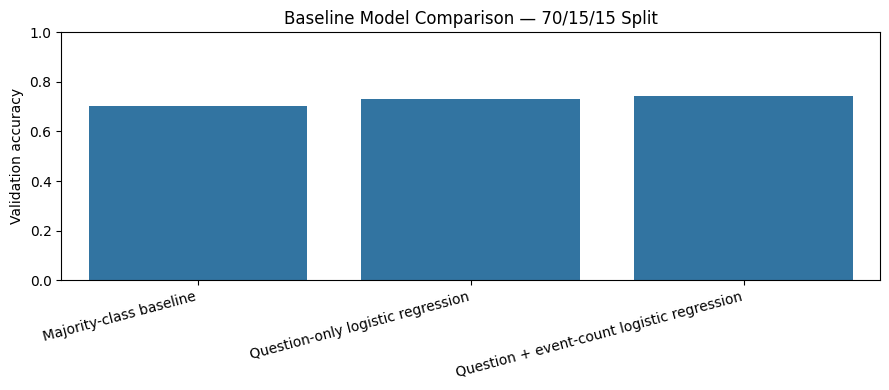

In [12]:
baseline_results = pd.DataFrame({ #compare all three models on the same validation set
    "Model": [
        "Majority-class baseline",
        "Question-only logistic regression",
        "Question + event-count logistic regression",
    ],
    "Accuracy": [
        majority_accuracy,
        question_accuracy,
        event_accuracy,
    ],
    "Precision": [
        majority_precision,
        question_precision,
        event_precision,
    ],
    "Recall": [
        majority_recall,
        question_recall,
        event_recall,
    ],
    "F1-score": [
        majority_f1,
        question_f1,
        event_f1,
    ]
})

display(baseline_results.round(4))

plt.figure(figsize = (9, 4)) #plot validation accuracy for a visual comparison
sns.barplot(data = baseline_results, x = "Model", y = "Accuracy")
plt.ylim(0, 1)
plt.ylabel("Validation accuracy")
plt.xlabel("")
plt.title("Baseline Model Comparison — 70/15/15 Split")
plt.xticks(rotation = 15, ha = "right")
plt.tight_layout()
plt.show()